<a href="https://colab.research.google.com/github/MrNamu22/Spurious-Correlations-Explorer/blob/main/spurious_correlations_explorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
year = 1990
life_exp = 58.6
country = "India"
print(country, year, life_exp)

India 1990 58.6


In [2]:
print(year + 33)
print(life_exp * 2)
print(round(72.0 - life_exp, 1))

2023
117.2
13.4


In [3]:
years = [1990, 2000, 2010, 2020, 2023]
life = [58.6, 62.7, 67.2, 70.2, 72.0]

print(life[0])
print(life[4])
print(len(life))
print(round(life[4] - life[0], 1))

58.6
72.0
5
13.4


In [4]:
total = 0
for value in life:
    total = total + value

mean_life = total / len(life)
print(round(mean_life, 2))

66.14


In [5]:
def mean(values):
    total = 0
    for value in values:
        total = total + value
    return total / len(values)

print(round(mean(life), 2))
print(mean([2, 4, 6]))

66.14
4.0


In [6]:
import pandas as pd

url = "https://ourworldindata.org/grapher/life-expectancy.csv?v=1&csvType=full&useColumnShortNames=true"

life_raw = pd.read_csv(url, storage_options={"User-Agent": "Mozilla/5.0"})

print(life_raw.shape)
life_raw.head()

(21565, 4)


,entity,code,year,life_expectancy_0
0,Afghanistan,AFG,1950,28.1563
1,Afghanistan,AFG,1951,28.5836
2,Afghanistan,AFG,1952,29.0138
3,Afghanistan,AFG,1953,29.4521
4,Afghanistan,AFG,1954,29.6975


In [7]:
is_india = life_raw["entity"] == "India"
in_range = (life_raw["year"] >= 1990) & (life_raw["year"] <= 2023)

life_india = life_raw[is_india & in_range]

print(life_india.shape)
life_india.head()

(34, 4)


,entity,code,year,life_expectancy_0
8539,India,IND,1990,58.6184
8540,India,IND,1991,59.0324
8541,India,IND,1992,59.4450
8542,India,IND,1993,59.8230
8543,India,IND,1994,60.2372


In [8]:
life_india = life_india.set_index("year")
life_series = life_india["life_expectancy_0"]
life_series.name = "life_expectancy"

print(life_series.head())
print(life_series[2023])
print(round(life_series.mean(), 2))
print(round(mean(life_series), 2))

year
1990    58.6184
1991    59.0324
1992    59.4450
1993    59.8230
1994    60.2372
Name: life_expectancy, dtype: float64
72.0026
65.39
65.39


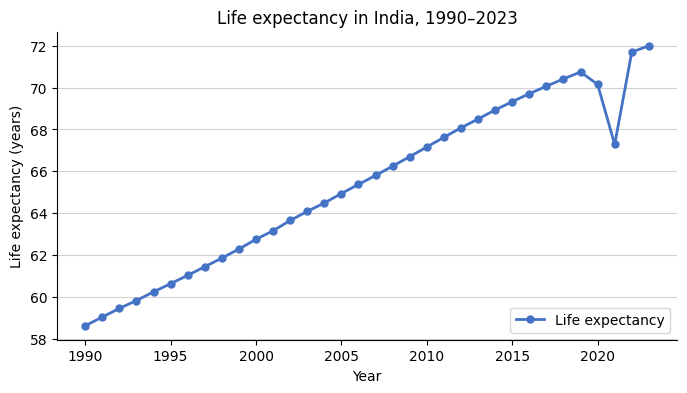

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(life_series.index, life_series.values,
         color="#4472C4", linewidth=2, marker="o", markersize=5,
         label="Life expectancy")
plt.title("Life expectancy in India, 1990–2023")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.grid(axis="y", color="lightgray")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.legend(loc="lower right")
plt.show()

In [10]:
def load_india(url, name):
    raw = pd.read_csv(url, storage_options={"User-Agent": "Mozilla/5.0"})
    mask = (raw["entity"] == "India") & (raw["year"] >= 1990) & (raw["year"] <= 2023)
    india = raw[mask].set_index("year")
    value_column = raw.columns[3]
    series = india[value_column]
    series.name = name
    return series

banana_url = "https://ourworldindata.org/explorers/global-food.csv?v=1&csvType=full&useColumnShortNames=true&Food=Bananas&Metric=Food+available+for+consumption&Per+capita=true&Unit=Kilograms+per+year"

bananas = load_india(banana_url, "bananas")

print(len(bananas))
print(bananas.head())
print(bananas.tail())

34
year
1990    6.619856
1991    7.109422
1992    7.546621
1993    8.630533
1994    9.083760
Name: bananas, dtype: float64
year
2019    17.42
2020    18.60
2021    18.51
2022    19.21
2023    20.12
Name: bananas, dtype: float64


In [11]:
df = pd.concat([bananas, life_series], axis=1)
print(df.head())

r = df["bananas"].corr(df["life_expectancy"])
print(round(r, 2))

       bananas  life_expectancy
year                           
1990  6.619856          58.6184
1991  7.109422          59.0324
1992  7.546621          59.4450
1993  8.630533          59.8230
1994  9.083760          60.2372
0.94


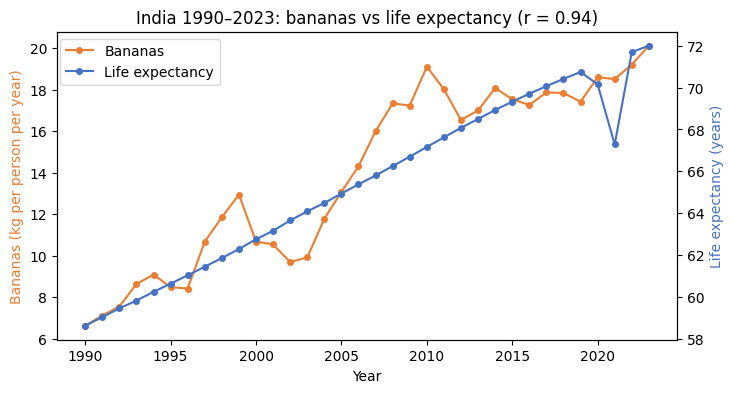

In [12]:
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(df.index, df["bananas"], color="#ED7D31", marker="o", markersize=4, label="Bananas")
ax1.set_xlabel("Year")
ax1.set_ylabel("Bananas (kg per person per year)", color="#ED7D31")

ax2 = ax1.twinx()
ax2.plot(df.index, df["life_expectancy"], color="#4472C4", marker="o", markersize=4, label="Life expectancy")
ax2.set_ylabel("Life expectancy (years)", color="#4472C4")

plt.title("India 1990–2023: bananas vs life expectancy (r = 0.94)")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.show()

In [13]:
base = "https://ourworldindata.org/grapher/"
opts = ".csv?v=1&csvType=full&useColumnShortNames=true"
food = "https://ourworldindata.org/explorers/global-food.csv?v=1&csvType=full&useColumnShortNames=true&Metric=Food+available+for+consumption&Per+capita=true"

urls = {
    "internet_share": base + "share-of-individuals-using-the-internet" + opts,
    "mobile_subs": base + "mobile-cellular-subscriptions-per-100-people" + opts,
    "internet_users": base + "number-of-internet-users" + opts,
    "rice_production": base + "rice-production" + opts,
    "sugar_cane": food + "&Food=Sugar+cane&Unit=Grams+per+day",
    "bananas": food + "&Food=Bananas&Unit=Kilograms+per+year",
    "co2": base + "annual-co2-emissions-per-country" + opts,
    "temp_anomaly": base + "annual-temperature-anomalies" + opts,
    "forest_share": base + "forest-area-as-share-of-land-area" + opts,
    "air_passengers": base + "air-passengers-carried" + opts,
    "tourist_trips": base + "international-tourist-trips" + opts,
    "life_expectancy": base + "life-expectancy" + opts,
    "gdp_per_capita": base + "gdp-per-capita-worldbank" + opts,
}

data = {}
for name, url in urls.items():
    data[name] = load_india(url, name)
    print(name, len(data[name]))

df_all = pd.DataFrame(data)

internet_share 33
mobile_subs 34
internet_users 33
rice_production 34
sugar_cane 34
bananas 34
co2 34
temp_anomaly 34
forest_share 34
air_passengers 34
tourist_trips 27
life_expectancy 34
gdp_per_capita 34


In [14]:
print(df_all.shape)
print(df_all.isna().sum())

for col in ["internet_share", "internet_users", "tourist_trips"]:
    missing_years = df_all.index[df_all[col].isna()].tolist()
    print(col, missing_years)

(34, 13)
internet_share     1
mobile_subs        0
internet_users     1
rice_production    0
sugar_cane         0
bananas            0
co2                0
temp_anomaly       0
forest_share       0
air_passengers     0
tourist_trips      7
life_expectancy    0
gdp_per_capita     0
dtype: int64
internet_share [1991]
internet_users [1991]
tourist_trips [1990, 1991, 1992, 1993, 1994, 2017, 2018]


In [15]:
df_all.to_csv("india_13_datasets_1990_2023.csv")

corr_matrix = df_all.corr()
print(corr_matrix.shape)
corr_matrix.round(2)

(13, 13)


,internet_share,mobile_subs,internet_users,rice_production,sugar_cane,bananas,co2,temp_anomaly,forest_share,air_passengers,tourist_trips,life_expectancy,gdp_per_capita
internet_share,1.00,0.76,1.00,0.91,0.31,0.69,0.87,0.43,0.79,0.78,0.31,0.75,0.89
mobile_subs,0.76,1.00,0.74,0.89,0.04,0.90,0.96,0.64,0.90,0.90,0.67,0.92,0.95
internet_users,1.00,0.74,1.00,0.90,0.32,0.68,0.86,0.42,0.78,0.77,0.30,0.73,0.88
rice_production,0.91,0.89,0.90,1.00,0.26,0.88,0.96,0.54,0.93,0.88,0.48,0.90,0.96
sugar_cane,0.31,0.04,0.32,0.26,1.00,0.14,0.14,0.04,0.11,0.12,-0.04,0.05,0.15
bananas,0.69,0.90,0.68,0.88,0.14,1.00,0.91,0.68,0.93,0.81,0.57,0.94,0.89
co2,0.87,0.96,0.86,0.96,0.14,0.91,1.00,0.67,0.96,0.94,0.64,0.96,1.00
temp_anomaly,0.43,0.64,0.42,0.54,0.04,0.68,0.67,1.00,0.70,0.67,0.50,0.72,0.67
forest_share,0.79,0.90,0.78,0.93,0.11,0.93,0.96,0.70,1.00,0.86,0.59,0.98,0.96
air_passengers,0.78,0.90,0.77,0.88,0.12,0.81,0.94,0.67,0.86,1.00,0.77,0.90,0.94


In [16]:
df_diff = df_all.diff()

print(df_all["bananas"].head(3))
print(df_diff["bananas"].head(3))
print(len(df_diff.dropna(subset=["bananas"])))

year
1990    6.619856
1991    7.109422
1992    7.546621
Name: bananas, dtype: float64
year
1990         NaN
1991    0.489566
1992    0.437199
Name: bananas, dtype: float64
33


In [17]:
r_levels = df_all["bananas"].corr(df_all["life_expectancy"])
r_diff = df_diff["bananas"].corr(df_diff["life_expectancy"])

print("Levels:     ", round(r_levels, 2))
print("Differences:", round(r_diff, 2))

Levels:      0.94
Differences: 0.06


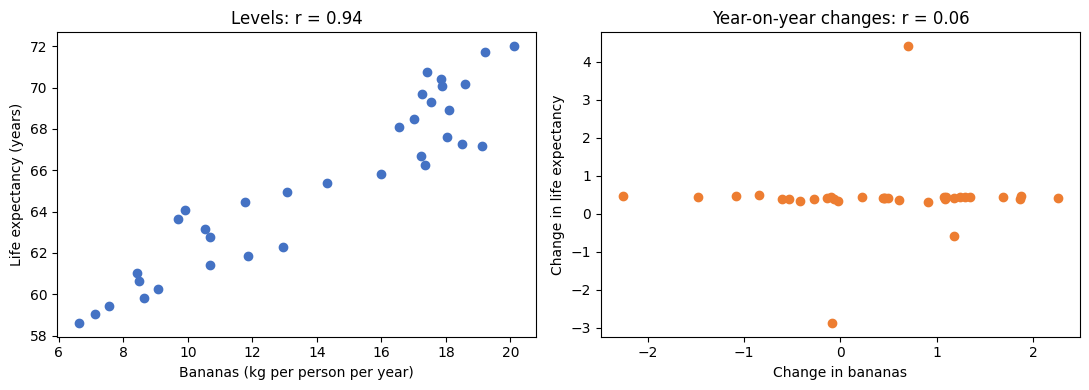

In [18]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.scatter(df_all["bananas"], df_all["life_expectancy"], color="#4472C4")
left.set_title("Levels: r = 0.94")
left.set_xlabel("Bananas (kg per person per year)")
left.set_ylabel("Life expectancy (years)")

right.scatter(df_diff["bananas"], df_diff["life_expectancy"], color="#ED7D31")
right.set_title("Year-on-year changes: r = 0.06")
right.set_xlabel("Change in bananas")
right.set_ylabel("Change in life expectancy")

plt.tight_layout()
plt.show()

In [19]:
def partial_corr(x, y, z):
    r_xy = x.corr(y)
    r_xz = x.corr(z)
    r_yz = y.corr(z)
    top = r_xy - r_xz * r_yz
    bottom = ((1 - r_xz**2) * (1 - r_yz**2)) ** 0.5
    return top / bottom

b = df_all["bananas"]
le = df_all["life_expectancy"]
gdp = df_all["gdp_per_capita"]

print("r(bananas, life):      ", round(b.corr(le), 2))
print("r(bananas, GDP):       ", round(b.corr(gdp), 2))
print("r(life, GDP):          ", round(le.corr(gdp), 2))
print("Partial, GDP removed:  ", round(partial_corr(b, le, gdp), 2))

r(bananas, life):       0.94
r(bananas, GDP):        0.89
r(life, GDP):           0.95
Partial, GDP removed:   0.66


In [20]:
import numpy as np

log_gdp = np.log(gdp)
year = pd.Series(df_all.index, index=df_all.index)

print("Control: GDP       ", round(partial_corr(b, le, gdp), 2))
print("Control: log(GDP)  ", round(partial_corr(b, le, log_gdp), 2))
print("Control: year      ", round(partial_corr(b, le, year), 2))

Control: GDP        0.66
Control: log(GDP)   0.26
Control: year       0.25


In [21]:
from scipy import stats

r1, p1 = stats.pearsonr(b, le)
print("Levels:      r =", round(r1, 2), " p =", p1)

d = df_diff[["bananas", "life_expectancy"]].dropna()
r2, p2 = stats.pearsonr(d["bananas"], d["life_expectancy"])
print("Differences: r =", round(r2, 2), " p =", round(p2, 2))

Levels:      r = 0.94  p = 1.4741392550734102e-16
Differences: r = 0.06  p = 0.73


In [22]:
from scipy import stats

r1, p1 = stats.pearsonr(b, le)
print("Levels:      r =", round(r1, 2), " p =", p1)

d = df_diff[["bananas", "life_expectancy"]].dropna()
r2, p2 = stats.pearsonr(d["bananas"], d["life_expectancy"])
print("Differences: r =", round(r2, 2), " p =", round(p2, 2))

Levels:      r = 0.94  p = 1.4741392550734102e-16
Differences: r = 0.06  p = 0.73


In [23]:
from itertools import combinations

cols = list(df_all.columns)
cols.remove("gdp_per_capita")

results = []
for x, y in combinations(cols, 2):
    pair = df_all[[x, y]].dropna()
    r, p = stats.pearsonr(pair[x], pair[y])
    results.append((x, y, r, p))

res_levels = pd.DataFrame(results, columns=["x", "y", "r", "p"])

print("Pairs tested:          ", len(res_levels))
print("Expected by chance:    ", 66 * 0.05)
print("Significant (p < 0.05):", (res_levels["p"] < 0.05).sum())

Pairs tested:           66
Expected by chance:     3.3000000000000003
Significant (p < 0.05): 53


In [24]:
def test_all_pairs(table):
    results = []
    for x, y in combinations(cols, 2):
        pair = table[[x, y]].dropna()
        r, p = stats.pearsonr(pair[x], pair[y])
        results.append((x, y, r, p))
    return pd.DataFrame(results, columns=["x", "y", "r", "p"])

res_diff = test_all_pairs(df_diff)

alpha = 0.05
bonferroni = alpha / 66

print("Bonferroni threshold:", round(bonferroni, 5))
print()
print("LEVELS       p < 0.05:", (res_levels["p"] < alpha).sum(),
      "  after Bonferroni:", (res_levels["p"] < bonferroni).sum())
print("DIFFERENCES  p < 0.05:", (res_diff["p"] < alpha).sum(),
      "  after Bonferroni:", (res_diff["p"] < bonferroni).sum())

Bonferroni threshold: 0.00076

LEVELS       p < 0.05: 53   after Bonferroni: 46
DIFFERENCES  p < 0.05: 13   after Bonferroni: 4


In [25]:
survivors = res_diff[res_diff["p"] < bonferroni].sort_values("p")
survivors

,x,y,r,p
1,internet_share,internet_users,0.998942,2.434701e-40
63,air_passengers,tourist_trips,0.900064,9.135415e-10
53,co2,air_passengers,0.783257,7.110069e-08
54,co2,tourist_trips,0.721888,4.630906e-05


In [26]:
df_pre = df_all.loc[:2019]
diff_pre = df_pre.diff()

print("Years used:", df_pre.index.min(), "to", df_pre.index.max())
print("Bananas vs life, levels:     ", round(df_pre["bananas"].corr(df_pre["life_expectancy"]), 2))
print("Bananas vs life, differences:", round(diff_pre["bananas"].corr(diff_pre["life_expectancy"]), 2))

res_pre = test_all_pairs(diff_pre)
print("Differences, p < 0.05:       ", (res_pre["p"] < alpha).sum())
print("Differences, Bonferroni:     ", (res_pre["p"] < bonferroni).sum())
res_pre[res_pre["p"] < bonferroni].sort_values("p")

Years used: 1990 to 2019
Bananas vs life, levels:      0.93
Bananas vs life, differences: -0.08
Differences, p < 0.05:        11
Differences, Bonferroni:      1


,x,y,r,p
1,internet_share,internet_users,0.998902,9.230690e-35


In [27]:
from sklearn.linear_model import LinearRegression

train = df_all.loc[:2009]
test = df_all.loc[2010:]

model = LinearRegression()
model.fit(train[["bananas"]], train["life_expectancy"])

print("Slope:    ", round(model.coef_[0], 3), "years of life per kg of bananas")
print("Intercept:", round(model.intercept_, 2))
print("R² on training years (1990–2009):", round(model.score(train[["bananas"]], train["life_expectancy"]), 2))
print("R² on unseen years (2010–2023):  ", round(model.score(test[["bananas"]], test["life_expectancy"]), 2))

Slope:     0.706 years of life per kg of bananas
Intercept: 54.75
R² on training years (1990–2009): 0.81
R² on unseen years (2010–2023):   -1.49


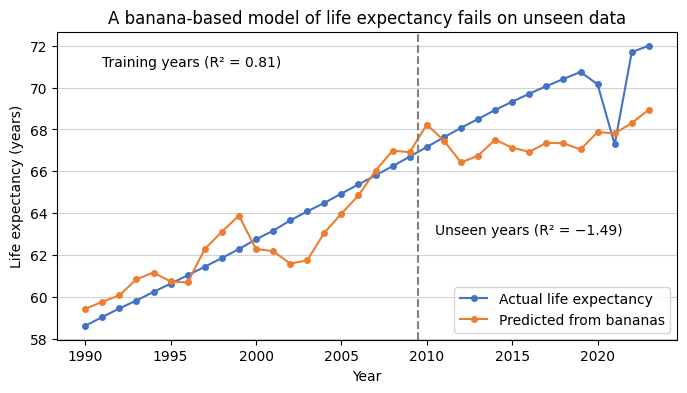

In [28]:
predicted = model.predict(df_all[["bananas"]])

plt.figure(figsize=(8, 4))
plt.plot(df_all.index, df_all["life_expectancy"], color="#4472C4", marker="o", markersize=4, label="Actual life expectancy")
plt.plot(df_all.index, predicted, color="#ED7D31", marker="o", markersize=4, label="Predicted from bananas")
plt.axvline(2009.5, color="gray", linestyle="--")
plt.text(1991, 71, "Training years (R² = 0.81)")
plt.text(2010.5, 63, "Unseen years (R² = −1.49)")
plt.title("A banana-based model of life expectancy fails on unseen data")
plt.xlabel("Year")
plt.ylabel("Life expectancy (years)")
plt.grid(axis="y", color="lightgray")
plt.legend(loc="lower right")
plt.savefig("model_failure.png", dpi=150, bbox_inches="tight")
plt.show()

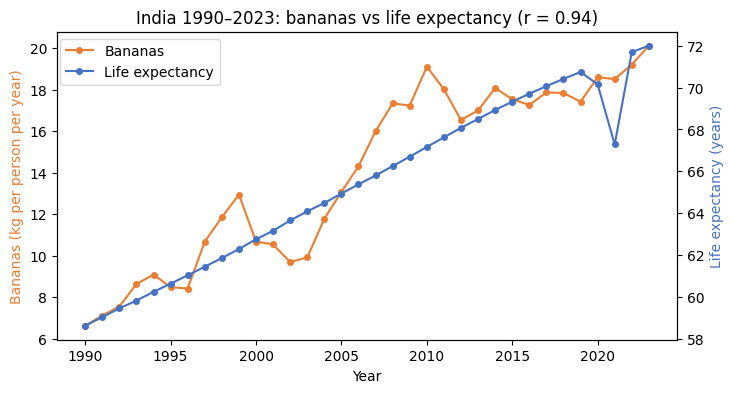

In [29]:
fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(df.index, df["bananas"], color="#ED7D31", marker="o", markersize=4, label="Bananas")
ax1.set_xlabel("Year")
ax1.set_ylabel("Bananas (kg per person per year)", color="#ED7D31")

ax2 = ax1.twinx()
ax2.plot(df.index, df["life_expectancy"], color="#4472C4", marker="o", markersize=4, label="Life expectancy")
ax2.set_ylabel("Life expectancy (years)", color="#4472C4")

plt.title("India 1990–2023: bananas vs life expectancy (r = 0.94)")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.savefig("bananas_vs_life.png", dpi=150, bbox_inches="tight")
plt.show()

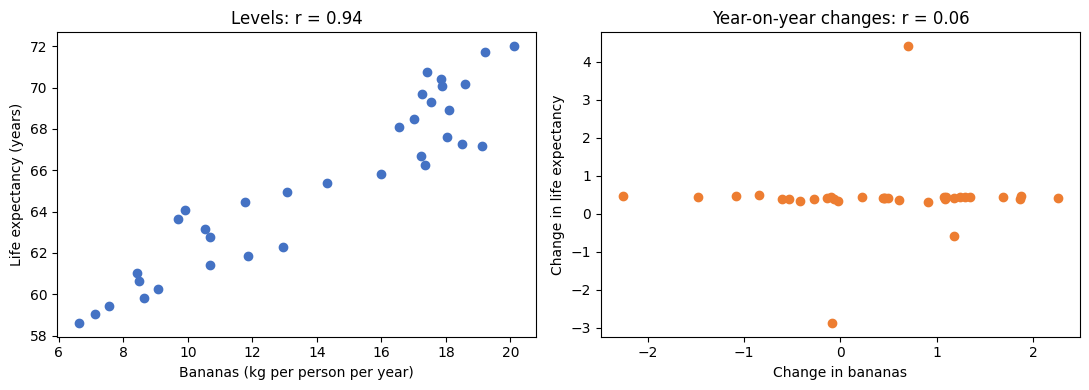

In [30]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.scatter(df_all["bananas"], df_all["life_expectancy"], color="#4472C4")
left.set_title("Levels: r = 0.94")
left.set_xlabel("Bananas (kg per person per year)")
left.set_ylabel("Life expectancy (years)")

right.scatter(df_diff["bananas"], df_diff["life_expectancy"], color="#ED7D31")
right.set_title("Year-on-year changes: r = 0.06")
right.set_xlabel("Change in bananas")
right.set_ylabel("Change in life expectancy")

plt.tight_layout()
plt.savefig("levels_vs_differences.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
import os
print(os.listdir())

['.config', 'bananas_vs_life.png', 'model_failure.png', 'levels_vs_differences.png', 'india_13_datasets_1990_2023.csv', 'sample_data']
